# K-Nearest Neighbours — CUB-200-2011 Tabular Attributes

Classifies 200 bird species from the 312 image-level attribute labels using k-nearest neighbours.

**Input:** the feature files written by [`dataPrep.ipynb`](dataPrep.ipynb) (ran first).
**Split:** the **official split** (`is_train`). The 80/20 version is [`knn_80_20.ipynb`](knn_80_20.ipynb).
**Protocol:** stratified 5-fold CV on the training set for all tuning and
selection; the test set is used once, at the end.

## 1. Setup

Stratified 5-fold CV (`RANDOM_STATE = 42`), accuracy as the selection metric, macro-F1 and top-5 accuracy reported alongside.

In [2]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

RANDOM_STATE = 42
SPLIT = 'is_train'  # official split; knn_80_20.ipynb uses 'is_train_80'
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
DATA = ROOT / 'data'
CUB = ROOT / 'CUB_200_2011'          # raw dataset folder used by dataPrep.ipynb (needed for the certainty experiments)
RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)
META_COLS = ['image_id', 'class_id', 'class_name', 'is_train', 'is_train_80']  # never used as features

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {'accuracy': 'accuracy', 'f1_macro': 'f1_macro'}


def load_table(name):
    """Full feature table for variant A, B or C, indexed by image_id."""
    path = DATA / f'cub_features_{name}.csv'
    if not path.exists():
        raise FileNotFoundError(f'{path} not found - run notebooks/dataPrep.ipynb first')
    return pd.read_csv(path, index_col='image_id').sort_index()


META = load_table('A')[['class_id', 'class_name', 'is_train', 'is_train_80']]
_feature_cache = {}


def features(name):
    """Feature matrix (all images) for variant 'A', 'B', 'C', or 'certainty' (see section 6)."""
    if name not in _feature_cache:
        if name == 'certainty':
            _feature_cache[name] = certainty_features()
        else:
            df = load_table(name)
            _feature_cache[name] = df[[c for c in df.columns if c not in META_COLS]]
    return _feature_cache[name]


def split_xy(X, split=SPLIT):
    """Split a feature matrix into X_train, y_train, X_test, y_test using a split column."""
    tr = META[split] == 1
    return X[tr], META.class_id[tr], X[~tr], META.class_id[~tr]


def load_variant(name, split=SPLIT):
    """Return X_train, y_train, X_test, y_test for feature variant A, B or C."""
    return split_xy(features(name), split)


X_train, y_train, X_test, y_test = load_variant('A')
class_names = META.groupby('class_id').class_name.first().sort_index()

print('train', X_train.shape, '| test', X_test.shape, '| classes', y_train.nunique())
print(f'chance accuracy: {1 / y_train.nunique():.3%}')

train (5994, 312) | test (5794, 312) | classes 200
chance accuracy: 0.500%


## 2. Meet the data

The same checks the lab ran on Iris (`load_iris()` gave 150 rows × 4 features, 3 species).

In [3]:
print('Shape of training data:', X_train.shape)
print('Shape of training target:', y_train.shape)
print('Number of species:', y_train.nunique())
print('\nFirst 10 feature names:', list(X_train.columns[:10]))
print('\nFirst 10 species:', list(class_names.head(10)))
print('\nValues in the data:', np.unique(X_train.values))

Shape of training data: (5994, 312)
Shape of training target: (5994,)
Number of species: 200

First 10 feature names: ['has_bill_shape::curved_(up_or_down)', 'has_bill_shape::dagger', 'has_bill_shape::hooked', 'has_bill_shape::needle', 'has_bill_shape::hooked_seabird', 'has_bill_shape::spatulate', 'has_bill_shape::all-purpose', 'has_bill_shape::cone', 'has_bill_shape::specialized', 'has_wing_color::blue']

First 10 species: ['001.Black_footed_Albatross', '002.Laysan_Albatross', '003.Sooty_Albatross', '004.Groove_billed_Ani', '005.Crested_Auklet', '006.Least_Auklet', '007.Parakeet_Auklet', '008.Rhinoceros_Auklet', '009.Brewer_Blackbird', '010.Red_winged_Blackbird']

Values in the data: [0 1]


In [4]:
# First five rows (first 8 attributes only)
X_train.iloc[:5, :8]

,has_bill_shape::curved_(up_or_down),has_bill_shape::dagger,has_bill_shape::hooked,has_bill_shape::needle,has_bill_shape::hooked_seabird,has_bill_shape::spatulate,has_bill_shape::all-purpose,has_bill_shape::cone
image_id,,,,,,,,
2,0,0,0,0,0,0,0,0
4,0,0,0,0,1,0,0,0
5,0,0,0,0,1,0,0,0
7,0,0,0,0,0,1,0,0
8,0,0,0,0,0,1,0,0


**Scaling:** every feature is 0/1 (−1/0/1 in variant B), so all features are already on the same scale.
KNN is distance-based, so this matters; no `StandardScaler` is needed.

## 3. First model (lab workflow)

Build, predict and evaluate. These test scores are shown for illustration only (as in the tutorial);
no setting is chosen from them (tuning uses CV in section 4).

In [5]:
knn = KNeighborsClassifier(n_neighbors=1)   # create the model
knn.fit(X_train, y_train)                   # KNN just stores the training data

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](200,)","[ 1, 2, 3,...,198,199,200]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [6]:
# Predictions next to the actual species (first 15 test birds)
y_pred_k1 = knn.predict(X_test)
examples = pd.DataFrame({
    'actual species': class_names.loc[y_test.values[:15]].values,
    'predicted species': class_names.loc[y_pred_k1[:15]].values,
})
examples['correct?'] = examples['actual species'] == examples['predicted species']
examples

,actual species,predicted species,correct?
0,001.Black_footed_Albatross,100.Brown_Pelican,False
1,001.Black_footed_Albatross,002.Laysan_Albatross,False
2,001.Black_footed_Albatross,127.Savannah_Sparrow,False
3,001.Black_footed_Albatross,053.Western_Grebe,False
4,001.Black_footed_Albatross,001.Black_footed_Albatross,True
5,001.Black_footed_Albatross,014.Indigo_Bunting,False
6,001.Black_footed_Albatross,015.Lazuli_Bunting,False
7,001.Black_footed_Albatross,050.Eared_Grebe,False
8,001.Black_footed_Albatross,046.Gadwall,False
9,001.Black_footed_Albatross,025.Pelagic_Cormorant,False


In [7]:
print('Test set score (k=1):          {:.3f}'.format(knn.score(X_test, y_test)))
print('Test set score (k=1, by hand): {:.3f}'.format(np.mean(y_pred_k1 == y_test.values)))

# The lab's summary repeated everything with k=11 (on Iris both scored 0.97)
knn11 = KNeighborsClassifier(n_neighbors=11).fit(X_train, y_train)
print('Test set score (k=11):         {:.3f}'.format(knn11.score(X_test, y_test)))

Test set score (k=1):          0.294
Test set score (k=1, by hand): 0.294
Test set score (k=11):         0.314


### 3.1 Baseline for tuning: default KNN (k=5), cross-validated

The reference point that tuning has to beat on CV.

In [8]:
baseline = KNeighborsClassifier()   # sklearn default: k=5, uniform weights, Euclidean distance
cv_base = cross_validate(baseline, X_train, y_train, cv=CV, scoring=SCORING,
                         return_train_score=True, n_jobs=-1)
print(f"train accuracy (CV folds): {cv_base['train_accuracy'].mean():.3f}")
print(f"CV accuracy:               {cv_base['test_accuracy'].mean():.3f} ± {cv_base['test_accuracy'].std():.3f}")
print(f"CV macro-F1:               {cv_base['test_f1_macro'].mean():.3f} ± {cv_base['test_f1_macro'].std():.3f}")

train accuracy (CV folds): 0.495
CV accuracy:               0.282 ± 0.008
CV macro-F1:               0.271 ± 0.011


> Our baseline KNN scores a test accuracy of 0.294 at k=1 and increases to 0.314 at k=11. The Iris dataset (in Lab week 1) gets exactly 97.0% accuracy for both k=1 and k=11. Iris features are clean and low-dimensional, with wide separations between a few classes. CUB has 200 species with massive overlap. At k=1, a single neighbor is often just a look-alike species from a different class. Increasing k averages out these random look-alike errors. However, making k too large will eventually blur the boundaries between distinct species.

## 4. Choosing k: grid search (variant A)

Grid over `n_neighbors`, `weights` and `metric`, selected on mean CV accuracy (refit on the whole training set).
Hamming distance is left out: on 0/1 data it ranks neighbours exactly like Manhattan (it is Manhattan divided by 312).

In [9]:
PARAM_GRID = {
    'n_neighbors': [1, 3, 5, 7, 11, 15, 21, 31, 51],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'cosine'],
}


def grid_search(estimator, grid, X, y, train_score=False):
    gs = GridSearchCV(estimator, grid, cv=CV, scoring=SCORING, refit='accuracy',
                      n_jobs=-1, return_train_score=train_score)
    return gs.fit(X, y)


t0 = time.time()
gs_A = grid_search(KNeighborsClassifier(), PARAM_GRID, X_train, y_train, train_score=True)
print(f"{len(gs_A.cv_results_['params'])} combinations x {CV.get_n_splits()} folds ({time.time() - t0:.0f}s)")
print('best params:', gs_A.best_params_)
print(f'best CV accuracy: {gs_A.best_score_:.3f}')


def top_results(gs, n=10):
    res = pd.DataFrame(gs.cv_results_)
    cols = [c for c in res.columns if c.startswith('param_')] + \
           ['mean_test_accuracy', 'std_test_accuracy', 'mean_test_f1_macro']
    return res.sort_values('rank_test_accuracy')[cols].head(n).round(4)


top_results(gs_A)

54 combinations x 5 folds (212s)
best params: {'metric': 'cosine', 'n_neighbors': 15, 'weights': 'distance'}
best CV accuracy: 0.345


,param_metric,param_n_neighbors,param_weights,mean_test_accuracy,std_test_accuracy,mean_test_f1_macro
47,cosine,15,distance,0.3452,0.0055,0.3319
45,cosine,11,distance,0.3430,0.0067,0.3304
49,cosine,21,distance,0.3415,0.0079,0.3267
46,cosine,15,uniform,0.3380,0.0070,0.3219
44,cosine,11,uniform,0.3373,0.0059,0.3203
43,cosine,7,distance,0.3370,0.0054,0.3260
51,cosine,31,distance,0.3303,0.0100,0.3135
48,cosine,21,uniform,0.3298,0.0073,0.3115
41,cosine,5,distance,0.3262,0.0057,0.3168
42,cosine,7,uniform,0.3247,0.0076,0.3095


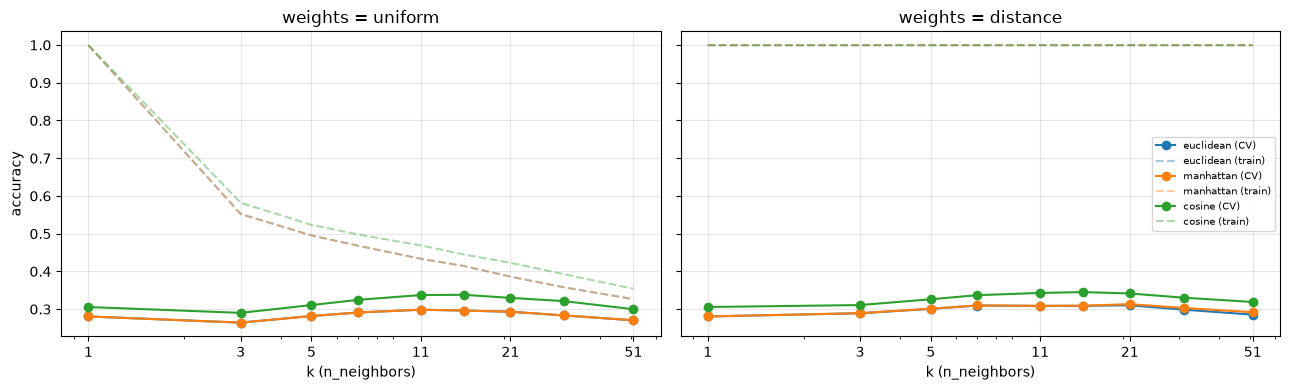

In [10]:
# How k affects train (dashed) and CV (solid) accuracy, from the grid search above
res = pd.DataFrame(gs_A.cv_results_)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, weights in zip(axes, ['uniform', 'distance']):
    for metric, colour in [('euclidean', 'tab:blue'), ('manhattan', 'tab:orange'), ('cosine', 'tab:green')]:
        r = res[(res.param_weights == weights) & (res.param_metric == metric)].sort_values('param_n_neighbors')
        ks = r.param_n_neighbors.astype(int)
        ax.plot(ks, r.mean_test_accuracy, 'o-', color=colour, label=f'{metric} (CV)')
        ax.plot(ks, r.mean_train_accuracy, '--', color=colour, alpha=0.4, label=f'{metric} (train)')
    ax.set(title=f'weights = {weights}', xlabel='k (n_neighbors)', xscale='log')
    ax.set_xticks([1, 3, 5, 11, 21, 51], ['1', '3', '5', '11', '21', '51'])
    ax.grid(alpha=0.3)
axes[0].set_ylabel('accuracy')
axes[1].legend(fontsize=7, loc='center right')
plt.tight_layout()
plt.show()

> In the uniform weighting panel, training accuracy drops steadily from 100% as k grows, whereas in the distance weighting panel, training accuracy stays at exactly 100% across all k values because scikit-learn gives the closest training sample all the vote when the distance is 0. For cosine distance with distance weighting, the cross-validation curve peaks at k = 15 with an accuracy of 0.3452. After the peak at k = 15, both curves gradually drop and level off at a lower performance tier as the model enters the underfitting zone.

## 5. Compare feature variants (A / B / C)

Same grid search on each "not visible" encoding from `dataPrep.ipynb` (A: 0/1, B: −1/0/1, C: A + 28 not-visible flags).
Each variant gets its own full grid search. A difference only matters if it is larger than the fold-to-fold standard deviation.

In [11]:
searches = {'A': gs_A}
for name in ['B', 'C']:
    Xv, yv, _, _ = load_variant(name)
    t0 = time.time()
    searches[name] = grid_search(KNeighborsClassifier(), PARAM_GRID, Xv, yv)
    print(f'{name} done ({time.time() - t0:.0f}s)')


def best_row(gs):
    i, r = gs.best_index_, gs.cv_results_
    return {'cv_accuracy': r['mean_test_accuracy'][i], 'cv_acc_std': r['std_test_accuracy'][i],
            'cv_f1_macro': r['mean_test_f1_macro'][i], 'best_params': str(gs.best_params_)}


variant_table = pd.DataFrame({k: best_row(v) for k, v in searches.items()}).T
variant_table

B done (50s)
C done (53s)


,cv_accuracy,cv_acc_std,cv_f1_macro,best_params
A,0.345179,0.005489,0.331917,"{'metric': 'cosine', 'n_neighbors': 15, 'weigh..."
B,0.19753,0.004528,0.18408,"{'metric': 'manhattan', 'n_neighbors': 7, 'wei..."
C,0.327995,0.006309,0.314918,"{'metric': 'cosine', 'n_neighbors': 15, 'weigh..."


In [12]:
BEST_VARIANT = variant_table.cv_accuracy.astype(float).idxmax()
print(f'selected variant: {BEST_VARIANT}  params: {searches[BEST_VARIANT].best_params_}')

selected variant: A  params: {'metric': 'cosine', 'n_neighbors': 15, 'weights': 'distance'}


> Variant A achieves 0.345 ± 0.005, Variant B drops heavily to 0.198 ± 0.005, and Variant C scores 0.328 ± 0.006, creating a maximum gap of 0.147 which is far larger than the fold-to-fold spread of 0.005–0.008. When a bird's body part is hidden, all the attributes for that body part (up to 15) become -1 in Variant B, forcing KNN to group photos based on shared occlusions rather than the actual bird species. Variant C avoids this by using just one single visibility flag per part instead of 15, leaking far less noise into the distance calculation and keeping it only slightly worse than A.

## 6. Improvement experiments

KNN-specific ideas, run on the selected variant and scored with the same CV. The best setup overall (including the plain
grid search from §5) is selected on CV accuracy.

| # | Idea |
|---|---|
| 1 | Plain KNN: best grid search from §5 |
| 2 | Jaccard distance (only counts attributes that at least one of the two birds has; 0/1 data only) |
| 3 | Certainty-weighted features: present → +confidence, absent → −confidence, not visible → 0 (confidence: guessing 0.5, probably 0.75, definitely 1) |
| 4 | Chi-squared feature selection, then KNN (0/1 data only) |
| 5 | Principal Component Analysis, then KNN |
| 6 | Linear Discriminant Analysis, then KNN |
| 7 | Certainty-weighted features + Linear Discriminant Analysis, then KNN |

In 4-7 the extra step only prepares the data; KNN makes every prediction. These steps sit inside a `Pipeline`,
so during CV they are fitted on the training folds only (no leakage).

In [13]:
def certainty_features():
    """Signed, certainty-weighted attributes built from the repaired annotation file used by dataPrep.ipynb."""
    path = CUB / 'attributes' / 'image_attribute_labels_clean.txt'
    if not path.exists():
        raise FileNotFoundError(f'{path} not found - the raw dataset must be in CUB_200_2011/ (as for dataPrep.ipynb)')
    ial = pd.read_csv(path, sep=r'\s+', header=None, usecols=[0, 1, 2, 3],
                      names=['image_id', 'attr_id', 'is_present', 'certainty'])
    confidence = {1: 0.0, 2: 0.5, 3: 0.75, 4: 1.0}   # 1 not visible, 2 guessing, 3 probably, 4 definitely
    ial['value'] = (2 * ial.is_present - 1) * ial.certainty.map(confidence)
    W = ial.pivot(index='image_id', columns='attr_id', values='value')
    W.columns = [f'cw_{c}' for c in W.columns]
    return W.loc[META.index]


def matrices(data, as_bool=False, split=SPLIT):
    """X_train, y_train, X_test, y_test for an experiment's input data."""
    Xtr, ytr, Xte, yte = split_xy(features(data), split)
    return (Xtr.astype(bool), ytr, Xte.astype(bool), yte) if as_bool else (Xtr, ytr, Xte, yte)


Xb_train, yb_train, _, _ = load_variant(BEST_VARIANT)
IS_BINARY = set(np.unique(Xb_train.values)) <= {0, 1}
n_feat = Xb_train.shape[1]
K_GRID = [5, 7, 11, 15, 21]
LDA_GRID = sorted({min(n, n_feat, yb_train.nunique() - 1) for n in [32, 64, 128, 199]})
PCA_GRID = [n for n in [20, 50, 100, 200] if n < n_feat]
KNN_AFTER = {'knn__n_neighbors': K_GRID, 'knn__weights': ['uniform', 'distance'],
             'knn__metric': ['euclidean', 'cosine']}

# name -> (fitted GridSearchCV, input data, use boolean input?)
experiments = {'1. Plain KNN (grid search)': (searches[BEST_VARIANT], BEST_VARIANT, False)}


def run(name, estimator, grid, data, as_bool=False):
    t0 = time.time()
    Xtr, ytr, _, _ = matrices(data, as_bool)
    experiments[name] = (grid_search(estimator, grid, Xtr, ytr), data, as_bool)
    print(f'{name} done ({time.time() - t0:.0f}s)')


if IS_BINARY:
    run('2. Jaccard distance', KNeighborsClassifier(metric='jaccard'),
        {'n_neighbors': K_GRID, 'weights': ['uniform', 'distance']}, BEST_VARIANT, as_bool=True)
else:
    print('2. skipped: Jaccard needs 0/1 data')

try:
    features('certainty')
    HAVE_CERTAINTY = True
except FileNotFoundError as e:
    HAVE_CERTAINTY = False
    print('3 and 7 skipped:', e)

if HAVE_CERTAINTY:
    run('3. Certainty-weighted features', KNeighborsClassifier(),
        {'n_neighbors': K_GRID, 'weights': ['uniform', 'distance'],
         'metric': ['euclidean', 'manhattan', 'cosine']}, 'certainty')

if IS_BINARY:
    run('4. Chi-squared selection + KNN',
        Pipeline([('select', SelectKBest(chi2)), ('knn', KNeighborsClassifier())]),
        {'select__k': [k for k in [50, 100, 150, 200, 250] if k < n_feat], **KNN_AFTER}, BEST_VARIANT)
else:
    print('4. skipped: chi-squared selection needs non-negative data')

run('5. PCA + KNN', Pipeline([('pca', PCA(random_state=RANDOM_STATE)), ('knn', KNeighborsClassifier())]),
    {'pca__n_components': PCA_GRID, **KNN_AFTER}, BEST_VARIANT)

run('6. LDA + KNN', Pipeline([('lda', LDA()), ('knn', KNeighborsClassifier())]),
    {'lda__n_components': LDA_GRID, **KNN_AFTER}, BEST_VARIANT)

if HAVE_CERTAINTY:
    run('7. Certainty-weighted + LDA + KNN', Pipeline([('lda', LDA()), ('knn', KNeighborsClassifier())]),
        {'lda__n_components': LDA_GRID, **KNN_AFTER}, 'certainty')

2. Jaccard distance done (25s)
3. Certainty-weighted features done (17s)
4. Chi-squared selection + KNN done (49s)
5. PCA + KNN done (37s)
6. LDA + KNN done (55s)
7. Certainty-weighted + LDA + KNN done (47s)


,cv_accuracy,cv_acc_std,cv_f1_macro,best_params,input
7. Certainty-weighted + LDA + KNN,0.437774,0.016118,0.411045,"{'knn__metric': 'cosine', 'knn__n_neighbors': ...",certainty
6. LDA + KNN,0.425763,0.019353,0.397086,"{'knn__metric': 'cosine', 'knn__n_neighbors': ...",A
5. PCA + KNN,0.354689,0.005419,0.337706,"{'knn__metric': 'cosine', 'knn__n_neighbors': ...",A
4. Chi-squared selection + KNN,0.353689,0.008843,0.33986,"{'knn__metric': 'cosine', 'knn__n_neighbors': ...",A
2. Jaccard distance,0.346346,0.006433,0.333986,"{'n_neighbors': 15, 'weights': 'distance'}",A
1. Plain KNN (grid search),0.345179,0.005489,0.331917,"{'metric': 'cosine', 'n_neighbors': 15, 'weigh...",A
3. Certainty-weighted features,0.313146,0.00683,0.300418,"{'metric': 'cosine', 'n_neighbors': 7, 'weight...",certainty


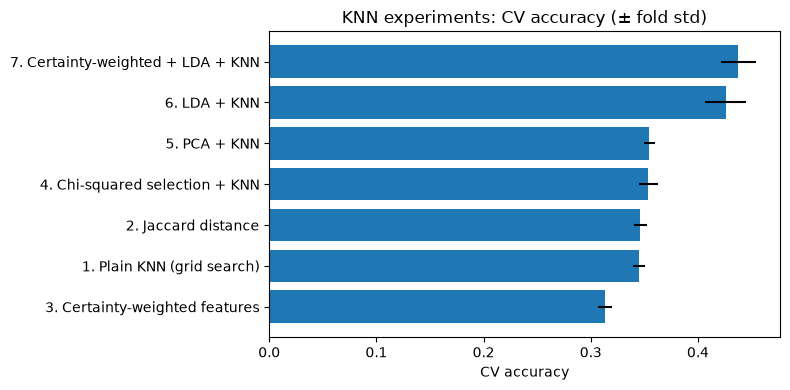

selected setup: 7. Certainty-weighted + LDA + KNN


In [14]:
experiment_table = pd.DataFrame({k: {**best_row(gs), 'input': data}
                                 for k, (gs, data, _) in experiments.items()}).T
experiment_table = experiment_table.sort_values('cv_accuracy', ascending=False)
display(experiment_table)

fig, ax = plt.subplots(figsize=(8, 4))
t = experiment_table.cv_accuracy.astype(float).sort_values()
ax.barh(t.index, t.values, xerr=experiment_table.loc[t.index, 'cv_acc_std'].astype(float), color='tab:blue')
ax.set(title='KNN experiments: CV accuracy (± fold std)', xlabel='CV accuracy')
plt.tight_layout()
plt.show()

BEST_SETUP = experiment_table.index[0]
print('selected setup:', BEST_SETUP)

> Experiment 7 (0.438 ± 0.016) and Experiment 6 (0.426 ± 0.019) give the highest results, but their fold-to-fold spreads overlap heavily (0.422–0.454 vs 0.407–0.445), so adding certainty weights does not provide a proven improvement over regular LDA. PCA (0.355 ± 0.005) provides dimensionality reduction by combining attributes, offering a small, borderline increase, while Chi-squared selection (0.354 ± 0.009) filters features directly but sits within the fold-to-fold noise floor of the baseline. Jaccard distance (0.346 ± 0.006) behaves identically to the plain cosine baseline (0.345 ± 0.005), staying completely inside the fold-to-fold spread. Experiment 3 does the worst (0.313 ± 0.007) because hidden body parts become 0 while visible-but-absent traits become negative, meaning the distance calculation partly measures what was visible in the photo; LDA rescues this in Experiment 7 because it uses species labels to learn which feature directions actually matter, allowing it to ignore this unhelpful noise.

## 7. Final evaluation on the test set

The only time the test set is used. The default KNN's test accuracy is printed alongside.

In [15]:
best_gs, best_data, best_bool = experiments[BEST_SETUP]
model = best_gs.best_estimator_
Xtr, ytr, Xte, yte = matrices(best_data, best_bool)

t0 = time.time()
y_pred = model.predict(Xte)
predict_time = time.time() - t0
proba = model.predict_proba(Xte)

results = {
    'setup': BEST_SETUP,
    'input_data': best_data,   # 'A', 'B', 'C', or 'certainty' (own encoding, section 6)
    'params': str(best_gs.best_params_),
    'train_accuracy': accuracy_score(ytr, model.predict(Xtr)),
    'cv_accuracy': best_gs.best_score_,
    'test_accuracy': accuracy_score(yte, y_pred),
    'test_f1_macro': f1_score(yte, y_pred, average='macro'),
    'test_top5_accuracy': top_k_accuracy_score(yte, proba, k=5, labels=model.classes_),
    'predict_time_s': predict_time,
}
baseline_test = accuracy_score(y_test, KNeighborsClassifier().fit(X_train, y_train).predict(X_test))
print(f'baseline (default KNN, variant A) test accuracy: {baseline_test:.3f}')
pd.Series(results).to_frame('tuned KNN')

baseline (default KNN, variant A) test accuracy: 0.302


,tuned KNN
setup,7. Certainty-weighted + LDA + KNN
input_data,certainty
params,"{'knn__metric': 'cosine', 'knn__n_neighbors': ..."
train_accuracy,0.999666
cv_accuracy,0.437774
test_accuracy,0.441664
test_f1_macro,0.421912
test_top5_accuracy,0.667069
predict_time_s,1.104414


In [16]:
# The same 15 test birds as in section 3: first model (k=1) vs final model
pd.DataFrame({
    'actual species': class_names.loc[yte.values[:15]].values,
    'first model (k=1)': class_names.loc[y_pred_k1[:15]].values,
    'final model': class_names.loc[y_pred[:15]].values,
})

,actual species,first model (k=1),final model
0,001.Black_footed_Albatross,100.Brown_Pelican,100.Brown_Pelican
1,001.Black_footed_Albatross,002.Laysan_Albatross,001.Black_footed_Albatross
2,001.Black_footed_Albatross,127.Savannah_Sparrow,001.Black_footed_Albatross
3,001.Black_footed_Albatross,053.Western_Grebe,008.Rhinoceros_Auklet
4,001.Black_footed_Albatross,001.Black_footed_Albatross,001.Black_footed_Albatross
5,001.Black_footed_Albatross,014.Indigo_Bunting,014.Indigo_Bunting
6,001.Black_footed_Albatross,015.Lazuli_Bunting,019.Gray_Catbird
7,001.Black_footed_Albatross,050.Eared_Grebe,001.Black_footed_Albatross
8,001.Black_footed_Albatross,046.Gadwall,046.Gadwall
9,001.Black_footed_Albatross,025.Pelagic_Cormorant,025.Pelagic_Cormorant


## 8. Error analysis

Most frequently confused species pairs, and per-species F1 (best, worst, histogram).

In [17]:
cm = confusion_matrix(yte, y_pred, labels=model.classes_)
np.fill_diagonal(cm, 0)  # keep only misclassifications
off = pd.DataFrame(cm, index=model.classes_, columns=model.classes_)
pairs = (off.stack().rename('count').reset_index()
           .rename(columns={'level_0': 'true', 'level_1': 'predicted'})
           .sort_values('count', ascending=False).head(15))
pairs['true'] = pairs.true.map(class_names)
pairs['predicted'] = pairs.predicted.map(class_names)
pairs.reset_index(drop=True)

,true,predicted,count
0,107.Common_Raven,029.American_Crow,16
1,184.Louisiana_Waterthrush,183.Northern_Waterthrush,15
2,030.Fish_Crow,029.American_Crow,13
3,054.Blue_Grosbeak,014.Indigo_Bunting,12
4,197.Marsh_Wren,195.Carolina_Wren,12
5,144.Common_Tern,141.Artic_Tern,11
6,025.Pelagic_Cormorant,023.Brandt_Cormorant,11
7,112.Great_Grey_Shrike,111.Loggerhead_Shrike,11
8,193.Bewick_Wren,195.Carolina_Wren,9
9,069.Rufous_Hummingbird,068.Ruby_throated_Hummingbird,9


Best classified species:
012.Yellow_headed_Blackbird    0.833
075.Green_Jay                  0.814
005.Crested_Auklet             0.800
057.Rose_breasted_Grosbeak     0.800
061.Heermann_Gull              0.800
189.Red_bellied_Woodpecker     0.794
010.Red_winged_Blackbird       0.787
191.Red_headed_Woodpecker      0.783

Worst classified species:
039.Least_Flycatcher               0.000
040.Olive_sided_Flycatcher         0.000
131.Vesper_Sparrow                 0.041
153.Philadelphia_Vireo             0.041
091.Mockingbird                    0.045
126.Nelson_Sharp_tailed_Sparrow    0.049
104.American_Pipit                 0.050
065.Slaty_backed_Gull              0.071


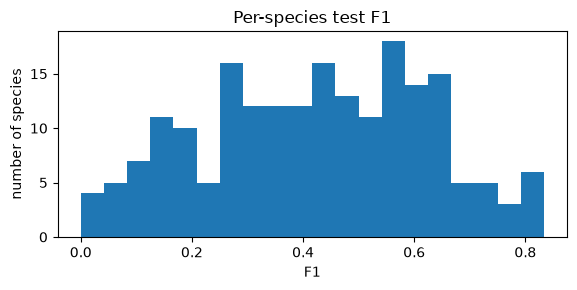

In [18]:
per_class = pd.Series(f1_score(yte, y_pred, average=None, labels=model.classes_),
                      index=class_names.loc[model.classes_].values, name='F1')
print('Best classified species:');  print(per_class.nlargest(8).round(3).to_string())
print('\nWorst classified species:'); print(per_class.nsmallest(8).round(3).to_string())

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(per_class, bins=20, color='tab:blue')
ax.set(title='Per-species test F1', xlabel='F1', ylabel='number of species')
plt.tight_layout()
plt.show()

> The model excels at identifying species with highly unique, bright colors or shapes that do not overlap with other classes, like the Yellow-headed Blackbird (0.833 F1 score) and Green Jay (0.814 F1 score), but fails completely on similar look-alikes like the Least Flycatcher and Olive-sided Flycatcher which both score an F1 of 0.000. Our highest confusion happens between the Common Raven and American Crow (16 counts), Louisiana and Northern Waterthrushes (15 counts), and Fish Crow and American Crow (13 counts), as these pairs share almost identical binary attributes that place them very close to each other in the cosine space. The fact that the highest confusion scores belong to birds that look nearly identical in real life suggests the misclassifications come mainly from the limitations of the attributes rather than the specific model setup.

## 9. Interpretation: nearest neighbours of misclassified birds

KNN has no rules or feature importances; its "explanation" for a prediction is the set of training birds it found closest.
For a few misclassified test birds, list the k neighbours that voted.

In [19]:
knn_step = model[-1] if isinstance(model, Pipeline) else model
Z_test = model[:-1].transform(Xte) if isinstance(model, Pipeline) else Xte
wrong = np.flatnonzero(y_pred != yte.values)[:3]

for i in wrong:
    row = Z_test[[i]] if isinstance(Z_test, np.ndarray) else Z_test.iloc[[i]]
    dist, idx = knn_step.kneighbors(row)
    print(f'Test bird {yte.index[i]}: actual {class_names[yte.values[i]]}, predicted {class_names[y_pred[i]]}')
    display(pd.DataFrame({'neighbour species': class_names.loc[ytr.values[idx[0]]].values,
                          'distance': dist[0].round(3)}))

Test bird 1: actual 001.Black_footed_Albatross, predicted 100.Brown_Pelican


,neighbour species,distance
0,100.Brown_Pelican,0.163
1,100.Brown_Pelican,0.179
2,101.White_Pelican,0.250
3,023.Brandt_Cormorant,0.263
4,100.Brown_Pelican,0.268
5,023.Brandt_Cormorant,0.278
6,023.Brandt_Cormorant,0.287


Test bird 10: actual 001.Black_footed_Albatross, predicted 008.Rhinoceros_Auklet


,neighbour species,distance
0,008.Rhinoceros_Auklet,0.011
1,052.Pied_billed_Grebe,0.015
2,086.Pacific_Loon,0.035
3,008.Rhinoceros_Auklet,0.058
4,053.Western_Grebe,0.059
5,002.Laysan_Albatross,0.075
6,053.Western_Grebe,0.078


Test bird 13: actual 001.Black_footed_Albatross, predicted 014.Indigo_Bunting


,neighbour species,distance
0,014.Indigo_Bunting,0.327
1,134.Cape_Glossy_Starling,0.332
2,014.Indigo_Bunting,0.340
3,014.Indigo_Bunting,0.345
4,014.Indigo_Bunting,0.356
5,054.Blue_Grosbeak,0.358
6,014.Indigo_Bunting,0.367


## 10. Summary

Headline numbers for the report (also saved to `results/`).

In [20]:
summary = pd.Series({'chance': 1 / y_train.nunique(), 'baseline test accuracy': baseline_test, **results})
summary.to_frame('KNN').to_csv(RESULTS / 'knn_results.csv')
experiment_table.to_csv(RESULTS / 'knn_experiments.csv')
summary

chance                                                                0.005
baseline test accuracy                                             0.302037
setup                                     7. Certainty-weighted + LDA + KNN
input_data                                                        certainty
params                    {'knn__metric': 'cosine', 'knn__n_neighbors': ...
train_accuracy                                                     0.999666
cv_accuracy                                                        0.437774
test_accuracy                                                      0.441664
test_f1_macro                                                      0.421912
test_top5_accuracy                                                 0.667069
predict_time_s                                                     1.104414
dtype: object

> Our final optimized model—Experiment 7 using certainty weighting combined with Linear Discriminant Analysis—achieved a top headline test accuracy of 0.442, a macro F1 score of 0.422, and a top-5 accuracy of 0.667, which sits far above the random chance baseline of 0.005. Plain KNN performs best using a cosine distance metric with distance weighting at k=15 (0.3452 CV accuracy), while lowering the neighbor count causes performance to drop. Encoding hidden body parts as -1 (Variant B) leaks severe visibility noise into the global distance calculations, while using a single visibility flag (Variant C) keeps this noise mild. While dimensionality reduction via PCA and feature selection via Chi-squared offer no clear gain beyond the fold-to-fold spread, LDA drastically improves performance by projecting the features to maximize class separability. Ultimately, the systematic confusion between highly similar crows, ravens, and flycatchers shows that the binary attributes lack the fine-grained visual details required to cleanly separate closely related species.

## 11. Limitations

> A key weakness of this study is the reliance on a single random seed for validation, which makes it difficult to fully trust small performance differences like the minor variance between Experiments 6 and 7. Additionally, our peak training accuracy hits 99.97% rather than a perfect 100%, indicating the presence of identical attribute vectors where different bird species share identical vectors, matching the 16 identical groups discovered during initial data preparation. Scalability is another limitation; prediction time takes roughly 1.1 seconds for 5,794 birds because KNN must exhaustively compare every test instance against the entire training set. The model also suffers from the curse of dimensionality due to its 312 raw attributes, though projecting the features down to 64 dimensions using LDA reduces the number of dimensions, which likely helps mitigate spatial sparseness. For future work, extracting raw continuous features using a deep learning convolutional network (like ResNet) could capture richer visual signatures, though hidden body parts will still present a challenge if they are physically obscured in the photos.